###Câu 1) Nhập dữ liệu, thống kê cơ bản, xử lý dữ liệu thiếu

In [1]:
def in_thong_tin():
    print("Họ và tên: Nguyễn Gia Huy")
    print("Mã sinh viên: 6451071027")
    print("-" * 30)

in_thong_tin()

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn import metrics
import seaborn as sns
import plotly as py
import plotly.graph_objs as go
import matplotlib.pyplot as plt
%matplotlib inline

duong_dan = 'Mall_Customers.csv'
data = pd.read_csv(duong_dan)

print("Kích thước:", data.shape)
print(data.head())
print("\nThông tin các cột:")
data.info()
print("\nThống kê mô tả:")
print(data.describe())

# Xử lý dữ liệu thiếu
print("\nSố giá trị thiếu mỗi cột:")
print(data.isnull().sum())

data = data.dropna()          # nếu có dòng thiếu thì loại bỏ
print("\nKích thước sau xử lý:", data.shape)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Kích thước: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Thông tin các cột:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 no

###Câu 2) Histogram của Tuổi, Thu nhập hằng năm, Số điểm mua sắm

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


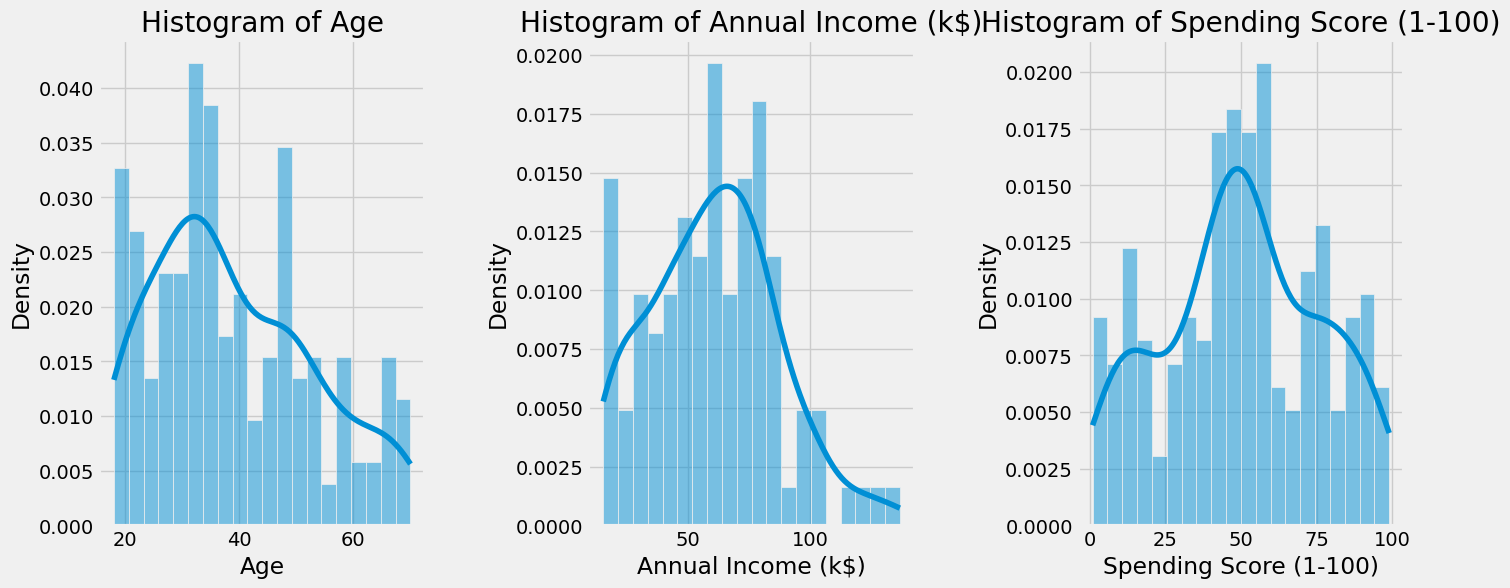

In [2]:
in_thong_tin()

plt.style.use('fivethirtyeight')
plt.figure(1, figsize=(15, 6))
n = 0
for x in ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace=0.5, wspace=0.5)
    sns.histplot(data[x], bins=20, kde=True, stat='density')
    plt.title('Histogram of {}'.format(x))
plt.show()

###Câu 3) Thống kê số mẫu theo Giới tính

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Gender
Female    112
Male       88
Name: count, dtype: int64


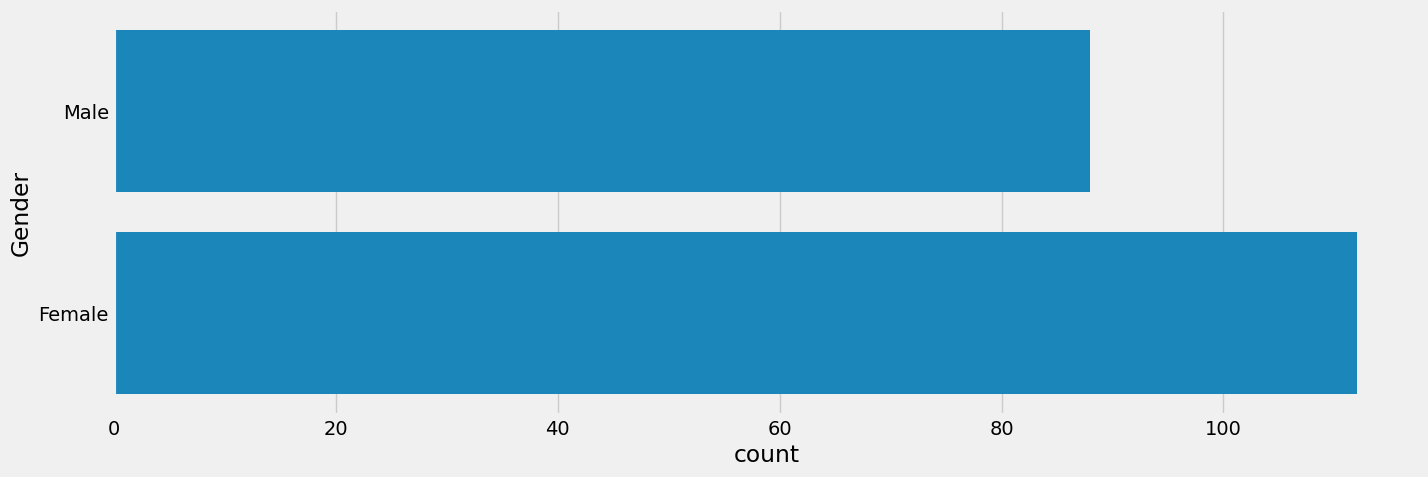

In [3]:
in_thong_tin()

print(data['Gender'].value_counts())

plt.figure(1, figsize=(15, 5))
sns.countplot(y='Gender', data=data)
plt.show()

###Câu 4) Scatter plot Tuổi và Thu nhập hằng năm theo Giới tính

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


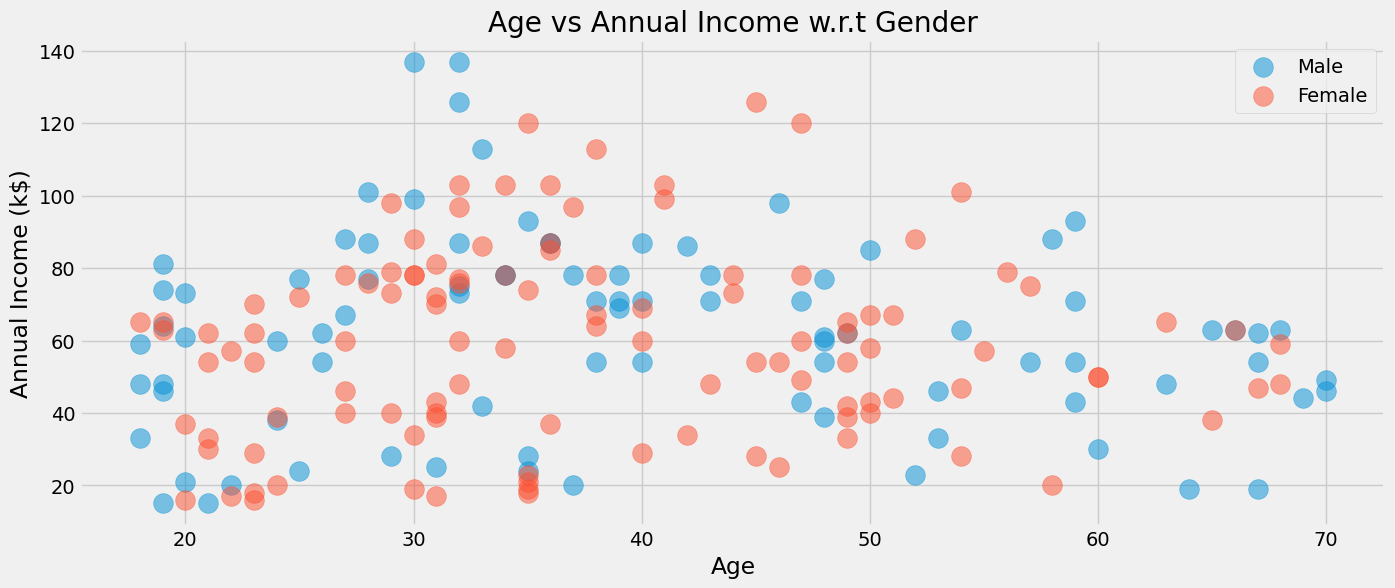

In [4]:
in_thong_tin()

plt.figure(1, figsize=(15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x='Age', y='Annual Income (k$)', data=data[data['Gender'] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel('Age'), plt.ylabel('Annual Income (k$)')
plt.title('Age vs Annual Income w.r.t Gender')
plt.legend()
plt.show()

###Câu 5) Scatter plot Thu nhập hằng năm và Số điểm mua sắm theo Giới tính

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


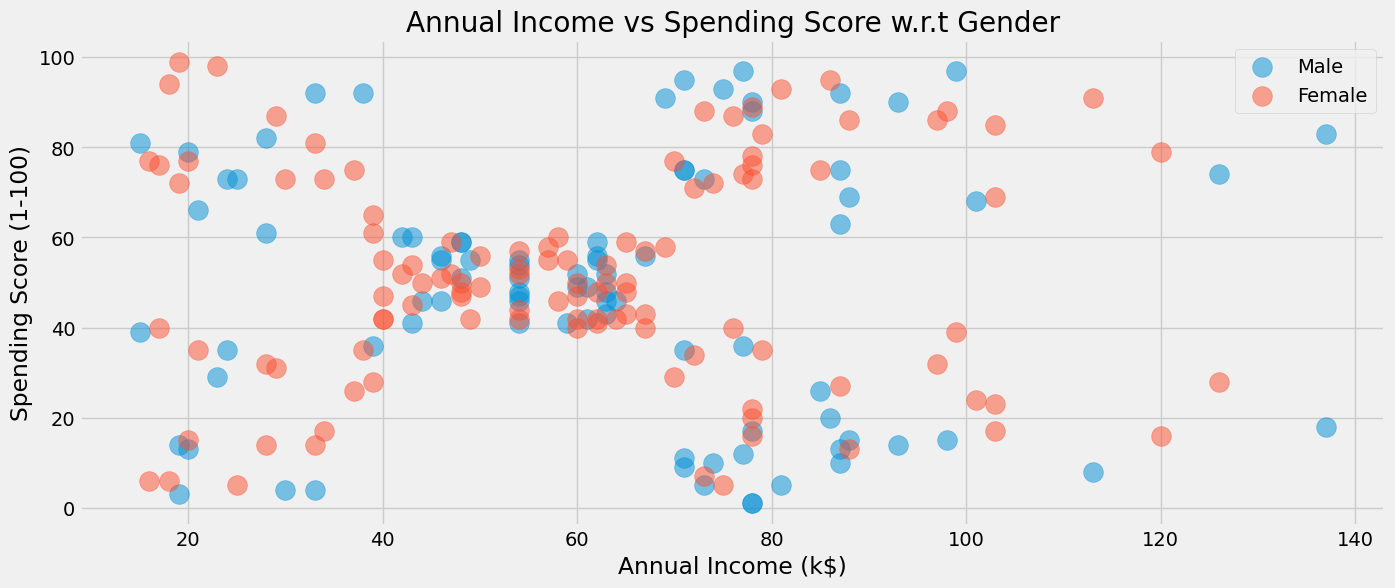

In [5]:
in_thong_tin()

plt.figure(1, figsize=(15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x='Annual Income (k$)', y='Spending Score (1-100)',
                data=data[data['Gender'] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel('Annual Income (k$)'), plt.ylabel('Spending Score (1-100)')
plt.title('Annual Income vs Spending Score w.r.t Gender')
plt.legend()
plt.show()

###Câu 6) Elbow và gom cụm k-Means theo Tuổi và Số điểm mua sắm

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


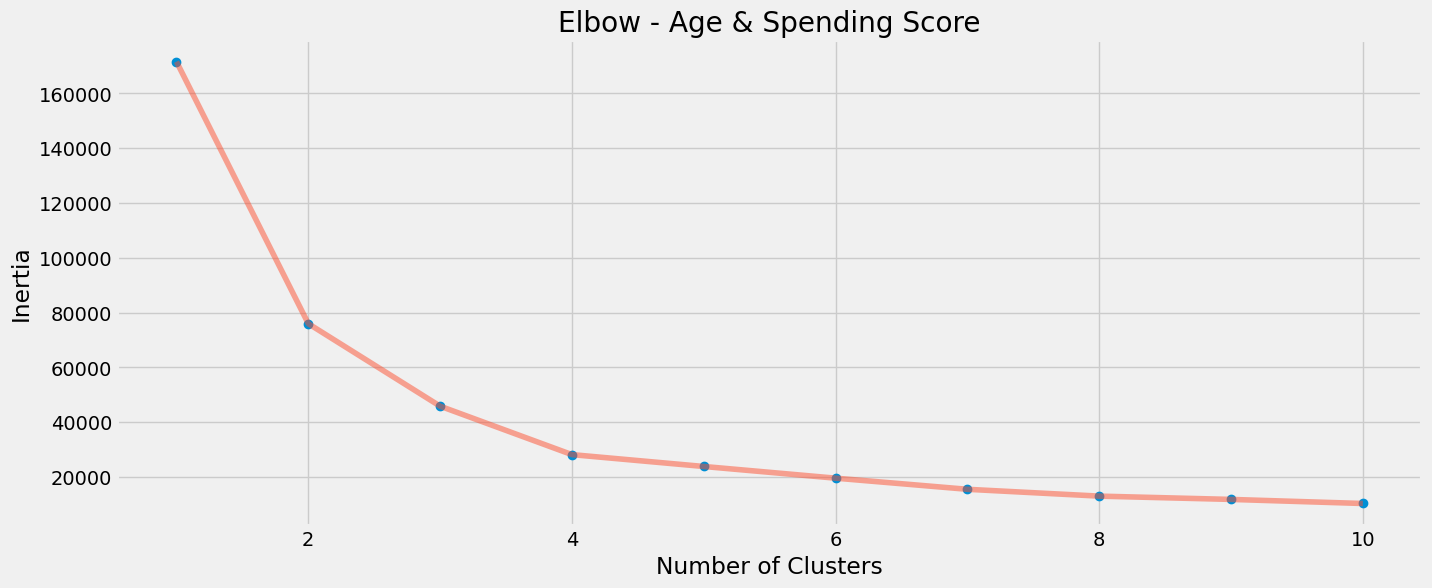

In [6]:
in_thong_tin()

X1 = data[['Age', 'Spending Score (1-100)']].iloc[:, :].values

# Phương pháp khuỷu tay
inertia = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init='random', random_state=42)
    algorithm.fit(X1)
    inertia.append(algorithm.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia, 'o')
plt.plot(np.arange(1, 11), inertia, '-', alpha=0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow - Age & Spending Score')
plt.show()

In [7]:
in_thong_tin()

k1 = 4     # số cụm chọn từ biểu đồ Elbow
algorithm = KMeans(n_clusters=k1, init='random', random_state=42)
algorithm.fit(X1)
labels1 = algorithm.labels_
centroids1 = algorithm.cluster_centers_

print("Số mẫu mỗi cụm:", np.bincount(labels1))
print("Tâm cụm:\n", centroids1)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Số mẫu mỗi cụm: [48 48 47 57]
Tâm cụm:
 [[55.70833333 48.22916667]
 [43.29166667 15.02083333]
 [27.61702128 49.14893617]
 [30.1754386  82.35087719]]


###Câu 7) Biểu diễn kết quả gom cụm bằng biểu đồ

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


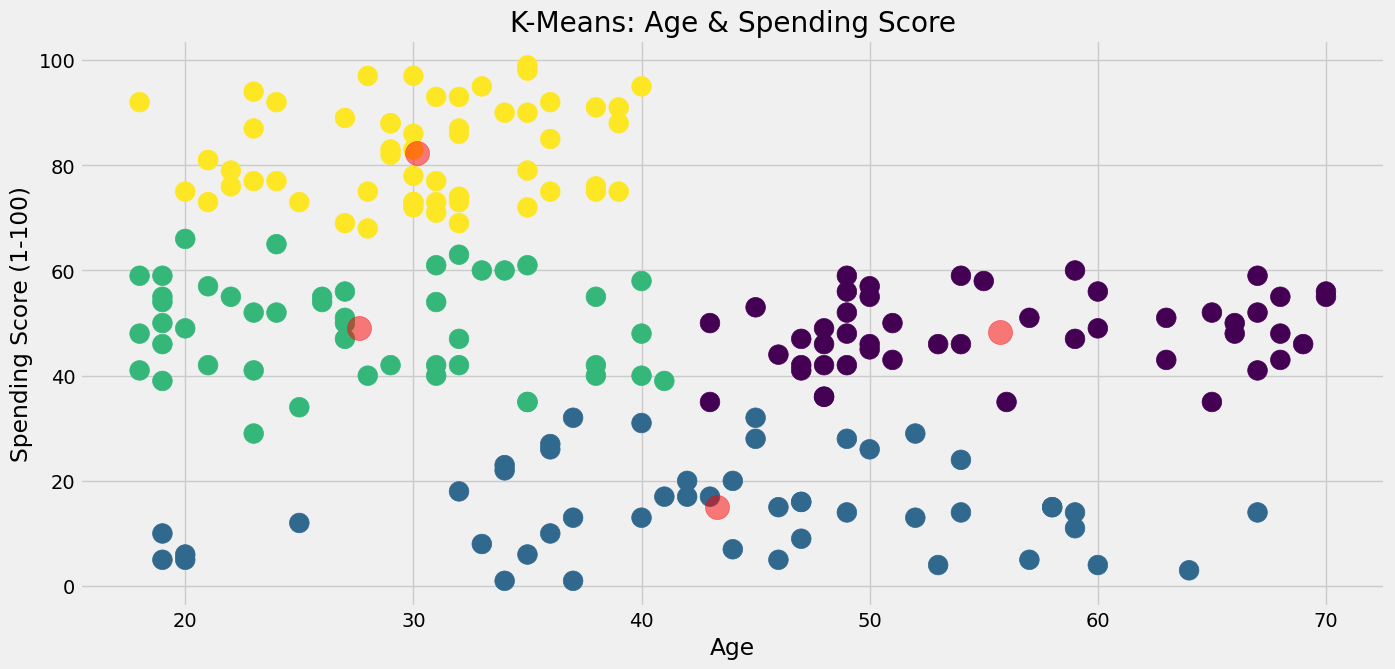

In [8]:
in_thong_tin()

plt.figure(1, figsize=(15, 7))
plt.clf()
plt.scatter(x='Age', y='Spending Score (1-100)', data=data, c=labels1, s=200)
plt.scatter(x=centroids1[:, 0], y=centroids1[:, 1], s=300, c='red', alpha=0.5)
plt.ylabel('Spending Score (1-100)'), plt.xlabel('Age')
plt.title('K-Means: Age & Spending Score')
plt.show()

###Câu 8) Đánh giá bằng Hệ số Dáng điệu (Silhouette)

In [9]:
in_thong_tin()

sil1 = metrics.silhouette_score(X1, labels1, metric='euclidean')
print("Silhouette (Age, Spending Score):", sil1)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Silhouette (Age, Spending Score): 0.49973941540141753


###Câu 9) Làm tương tự câu 6–8 cho hai trường hợp còn lại

####9.1) Thu nhập hằng năm và Số điểm mua sắm

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


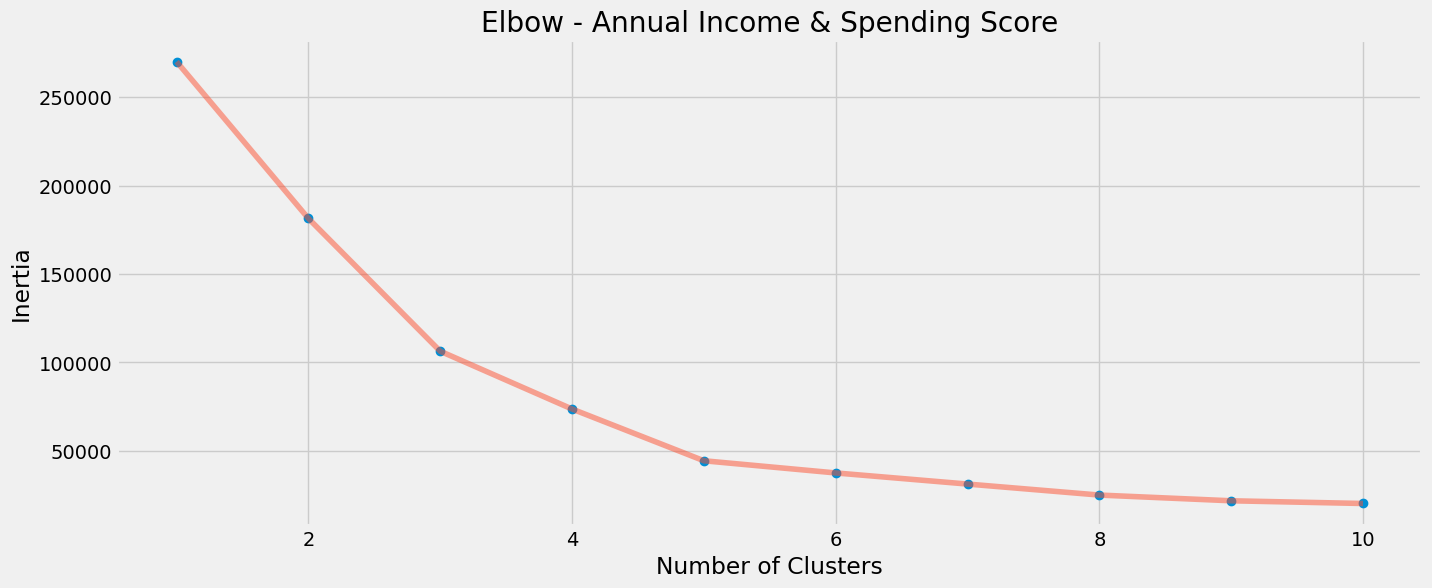

In [10]:
in_thong_tin()

X2 = data[['Annual Income (k$)', 'Spending Score (1-100)']].iloc[:, :].values

# Elbow
inertia2 = []
for n in range(1, 11):
    km = KMeans(n_clusters=n, init='random', random_state=42)
    km.fit(X2)
    inertia2.append(km.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia2, 'o')
plt.plot(np.arange(1, 11), inertia2, '-', alpha=0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow - Annual Income & Spending Score')
plt.show()

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


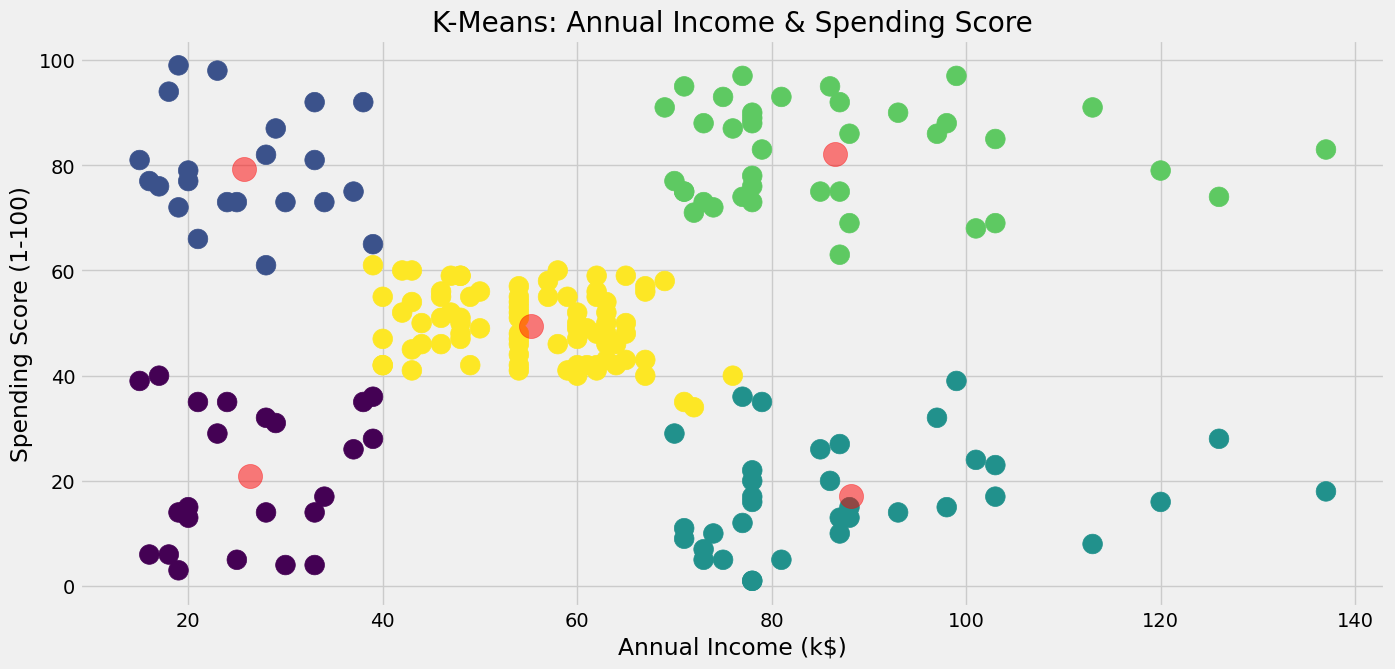

Silhouette (Annual Income, Spending Score): 0.553931997444648


In [11]:
in_thong_tin()

k2 = 5     # chọn theo biểu đồ Elbow ở cell trên (thường là 5 với dữ liệu này)
algorithm2 = KMeans(n_clusters=k2, init='random', random_state=42)
algorithm2.fit(X2)
labels2 = algorithm2.labels_
centroids2 = algorithm2.cluster_centers_

# Biểu diễn kết quả
plt.figure(1, figsize=(15, 7))
plt.clf()
plt.scatter(x='Annual Income (k$)', y='Spending Score (1-100)', data=data,
            c=labels2, s=200)
plt.scatter(x=centroids2[:, 0], y=centroids2[:, 1], s=300, c='red', alpha=0.5)
plt.xlabel('Annual Income (k$)'), plt.ylabel('Spending Score (1-100)')
plt.title('K-Means: Annual Income & Spending Score')
plt.show()

# Silhouette
sil2 = metrics.silhouette_score(X2, labels2, metric='euclidean')
print("Silhouette (Annual Income, Spending Score):", sil2)

####9.2) Tuổi, Thu nhập hằng năm và Số điểm mua sắm (3D)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


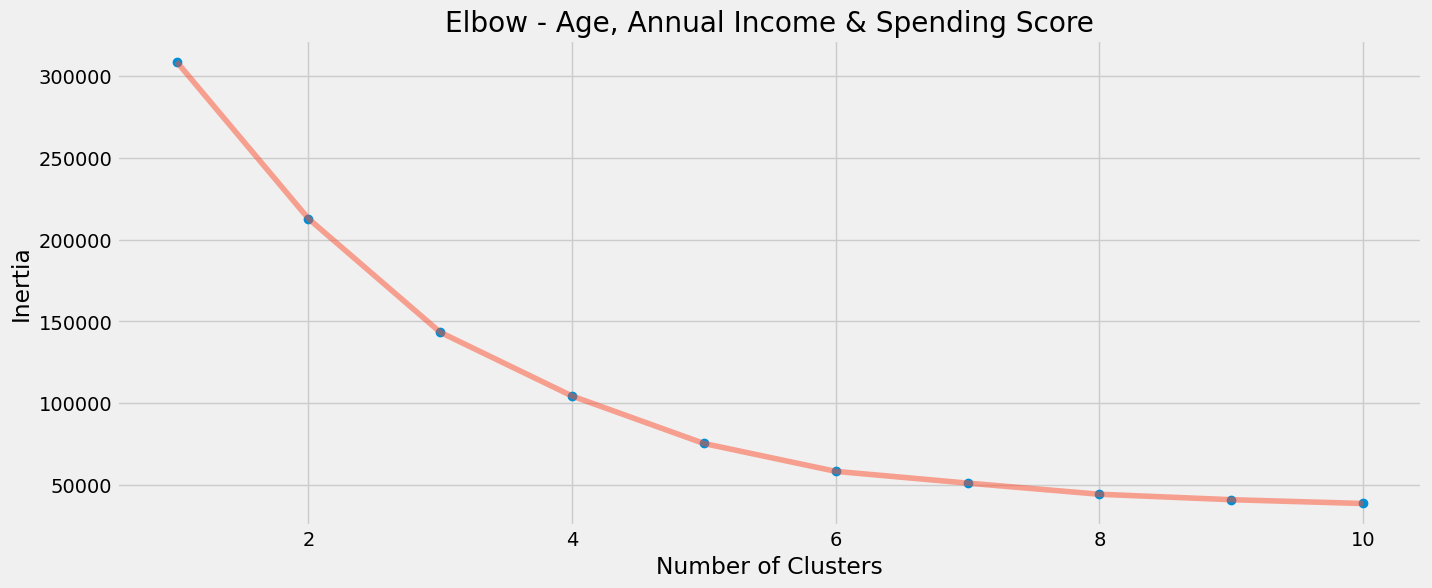

In [12]:
in_thong_tin()

X3 = data[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].iloc[:, :].values

# Elbow
inertia3 = []
for n in range(1, 11):
    km = KMeans(n_clusters=n, init='random', random_state=42)
    km.fit(X3)
    inertia3.append(km.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia3, 'o')
plt.plot(np.arange(1, 11), inertia3, '-', alpha=0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow - Age, Annual Income & Spending Score')
plt.show()

In [13]:
in_thong_tin()

k3 = 6     # chọn theo biểu đồ Elbow ở cell trên
algorithm3 = KMeans(n_clusters=k3, init='random', random_state=42)
algorithm3.fit(X3)
labels3 = algorithm3.labels_
centroids3 = algorithm3.cluster_centers_

# Biểu diễn 3D bằng plotly
data['label3'] = labels3
trace1 = go.Scatter3d(
    x=data['Age'],
    y=data['Spending Score (1-100)'],
    z=data['Annual Income (k$)'],
    mode='markers',
    marker=dict(
        color=data['label3'],
        size=8,
        line=dict(color=data['label3'], width=12),
        opacity=0.8
    )
)
layout = go.Layout(
    title='Clusters',
    scene=dict(
        xaxis=dict(title='Age'),
        yaxis=dict(title='Spending Score'),
        zaxis=dict(title='Annual Income')
    )
)
fig = go.Figure(data=[trace1], layout=layout)
fig.show()          # thay cho py.offline.iplot(fig) của tài liệu

# Silhouette
sil3 = metrics.silhouette_score(X3, labels3, metric='euclidean')
print("Silhouette (Age, Annual Income, Spending Score):", sil3)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


Silhouette (Age, Annual Income, Spending Score): 0.4523566166018854
